# 04 — Profile Clustering (GMM)

Component 3 (Learning Insight & Early Warning System) — Grade 2-3 mathematics dyscalculia,
synthetic research data. Kernel `Python (c3-ews)`, seed `20260828`.

**Cleared to proceed:** NB03 (SF-038) passed the leakage gate on all three feature spaces
(`dev_docs/notebook_findings/03_leakage_audit_findings.md`). This notebook has its own gate,
independent of SF-038:

```
ARI(cluster, population) < 0.30      (CL-5, docs/08 §5)
```

**Purpose.** Find LEARNING PROFILES — the *shape* of a learner's skill pattern (which skills are
relatively strong or weak for that learner) — not severity tiers. A clustering that just sorts
learners strong-to-weak has **failed**, even if BIC looks clean and clusters look tidy, because doc
08 §1 records exactly that failure in the previous build: one cluster ≈100% typically developing,
another ≈94% dyscalculic, because clustering was fit on raw severity instead of shape.

This is why `CLUSTER_FEATURES` are **ipsatised**: each `ipsatised_mastery_<skill>` is that skill's
mastery minus the *learner's own row-wise mean across skills at that snapshot* (verified below —
the 7-column row mean is ~1e-17, i.e. exactly zero up to float error). Ipsatisation removes overall
level and leaves relative shape. Every result below is judged against one question: **is this a
profile, or a severity ranking wearing a profile's clothes?**

**Features — 8, not 11.** `CLUSTER_FEATURES` in `nbconfig.py` is `ipsatised_mastery_*` (7 skills) +
`number_sense_minus_operations`. `error_type_profile[3]` stays uncomputed — doc 06 never defines the
bucket mapping, and NB03 §6 explicitly excludes it. We do not invent one here.

**Read first (context only, not re-derived):**
- `dev_docs/notebook_findings/03_leakage_audit_findings.md` §6 — this notebook's task list, carried
  from the SF-038 review.
- `dev_docs/notebook_findings/02_preprocessing_findings.md` §8 — the cluster-feature PCA (CL-3),
  already computed and passing. Reused, not recomputed, in §D below.
- `docs/08_LEAKAGE_AND_SAFETY_RULES.md` §5 — CL-1..CL-7, the rules this notebook exists to satisfy.

**Do NOT model the target here** — that is NB05. **Do NOT run any git command** — the human handles
all git.

In [1]:
import sys
from pathlib import Path
NB_DIR = Path.cwd()
sys.path.insert(0, str(NB_DIR))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from nbconfig import (
    RANDOM_SEED, TABLES_DIR, FIGURES_DIR, MODELS_DIR,
    FEATURE_MATRIX_PATH, AUDIT_LABELS_PATH, CLUSTER_FEATURES,
)

np.random.seed(RANDOM_SEED)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

print("seed:", RANDOM_SEED)
print("CLUSTER_FEATURES (8):", CLUSTER_FEATURES)
assert len(CLUSTER_FEATURES) == 8

seed: 20260828
CLUSTER_FEATURES (8): ['ipsatised_mastery_counting', 'ipsatised_mastery_number_sense', 'ipsatised_mastery_place_value', 'ipsatised_mastery_addition', 'ipsatised_mastery_subtraction', 'ipsatised_mastery_multiplication', 'ipsatised_mastery_division', 'number_sense_minus_operations']


## 1. Load data and assemble the cluster-feature table

NB02's `24_engineered_feature_matrix.csv` carries `student_id`, `t`, `split` and the 62 *model*
features, but not the 8 ipsatised cluster features — those aren't model-role columns and NB02 never
merged them in. They live in the raw per-`t` feature matrix (`feature_matrix_at_t_...csv`, 7,500
rows = 300 learners × 25 sessions). We inner-merge on `(student_id, t)`, restricting to the same 9
`t` values NB02 used (3, 5, …, 19), which reproduces NB02's 2,700-row panel and its train/test split
— verified below, not assumed.

In [2]:
engineered = pd.read_csv(TABLES_DIR / "24_engineered_feature_matrix.csv")
assert engineered.shape == (2700, 62)

raw_at_t = pd.read_csv(FEATURE_MATRIX_PATH)
print("raw_at_t:", raw_at_t.shape, "| t values:", sorted(raw_at_t["t"].unique()))

t_keep = sorted(engineered["t"].unique())
print("engineered t values:", t_keep)

cluster_cols = ["student_id", "t"] + CLUSTER_FEATURES
raw_cluster = raw_at_t.loc[raw_at_t["t"].isin(t_keep), cluster_cols]

df = engineered[["student_id", "t", "split"]].merge(
    raw_cluster, on=["student_id", "t"], how="left", validate="one_to_one"
)
assert df.shape == (2700, 3 + 8)
assert df[CLUSTER_FEATURES].isnull().sum().sum() == 0
assert df["student_id"].nunique() == 300

# CL-4 / population hygiene: population must never be a fitting input. Confirm it is not
# present anywhere in the working frame before any model touches it.
assert "population" not in df.columns and "dd_subtype" not in df.columns

# Ipsatisation check: row mean across the 7 skills is ~0 (float noise only) — confirms the
# "each skill minus the learner's own row mean" definition, i.e. level is removed by construction.
skill7 = [c for c in CLUSTER_FEATURES if c.startswith("ipsatised_mastery_")]
row_mean_abs = df[skill7].mean(axis=1).abs()
print("row-mean-of-7-ipsatised-skills |max|:", row_mean_abs.max())
assert row_mean_abs.max() < 1e-8

df.head()

raw_at_t: (7500, 33) | t values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]
engineered t values: [np.int64(3), np.int64(5), np.int64(7), np.int64(9), np.int64(11), np.int64(13), np.int64(15), np.int64(17), np.int64(19)]
row-mean-of-7-ipsatised-skills |max|: 1.5067312477055697e-16


,student_id,t,split,ipsatised_mastery_counting,ipsatised_mastery_number_sense,ipsatised_mastery_place_value,ipsatised_mastery_addition,ipsatised_mastery_subtraction,ipsatised_mastery_multiplication,ipsatised_mastery_division,number_sense_minus_operations
0,STU-0001,3,test,0.057262,0.131936,-0.037840,-0.037840,-0.037840,-0.037840,-0.037840,0.169776
1,STU-0001,5,test,0.124630,0.101669,-0.045260,-0.045260,-0.045260,-0.045260,-0.045260,0.146929
2,STU-0001,7,test,0.184220,0.128563,-0.062557,-0.062557,-0.062557,-0.062557,-0.062557,0.191119
3,STU-0001,9,test,0.190137,0.093060,-0.056639,-0.056639,-0.056639,-0.056639,-0.056639,0.149700
4,STU-0001,11,test,0.239669,0.178848,-0.083703,-0.083703,-0.083703,-0.083703,-0.083703,0.262551


## A. Unit of clustering

**Decision: fit the GMM at snapshot level (2,700 rows).** Snapshots are the unit doc 06's shape
features are computed on, and fitting there uses the full temporal spread of each learner's profile
rather than collapsing it before we've looked at it.

**But 2,700 is not 2,700 independent observations.** Each learner contributes 9 strongly
autocorrelated snapshots — the same learner's profile shape one `t` apart is far more similar than
two random rows. Effective n for anything claiming statistical weight (the k sweep's BIC, the
silhouette score, the stability check) is closer to **300** than 2,700, and we do not treat the
2,700-row scale as 2,700 pieces of evidence anywhere below, including when reading the k-sweep
curves.

For the ARI gate specifically — a learner-level comparison against a learner-level label
(`population`) — each learner is reduced to **one cluster via modal assignment across their 9
snapshots** (§C). How often a learner's own snapshots disagree on cluster is reported directly: a
profile that flips from session to session is not a stable profile, gate or no gate.

In [3]:
X = df[CLUSTER_FEATURES].to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("feature means (pre-scale):", np.round(df[CLUSTER_FEATURES].mean().to_numpy(), 4))
print("feature stds  (pre-scale):", np.round(df[CLUSTER_FEATURES].std().to_numpy(), 4))

# Fit on all 2,700 snapshots. This is unsupervised profiling, not a predictive model being
# generalisation-tested — there is no held-out target to protect, and the train/test split
# NB02/NB03 defined is a supervised-modelling artefact (kept on `df["split"]` only so NB05 can
# still condition on it later, e.g. for its own leakage bookkeeping). SF-038's grouped-split
# concern does not apply to fitting a mixture model; it applies to *evaluating prediction of
# population*, which happens only in §C below, read-only, against a model that was never fit on it.

feature means (pre-scale): [ 0.0542  0.0762 -0.0091  0.0241  0.0333 -0.0826 -0.0961  0.1065]
feature stds  (pre-scale): [0.155  0.1461 0.0954 0.1155 0.1061 0.0851 0.0723 0.2068]


## B. K sweep (k = 2..8)

`GaussianMixture`, `covariance_type='full'`, `n_init=10`, seeded. BIC and AIC per k, plus silhouette
(on the hard `predict()` labels) for context — silhouette is not the selection criterion (it
penalises the soft, overlapping structure CL-6 asks us to keep), but a very low value is still a
useful flag.

In [4]:
K_RANGE = list(range(2, 9))
sweep_rows = []
gmm_by_k = {}

for k in K_RANGE:
    gmm = GaussianMixture(
        n_components=k, covariance_type="full", n_init=10,
        random_state=RANDOM_SEED, max_iter=300,
    )
    gmm.fit(X_scaled)
    labels_k = gmm.predict(X_scaled)
    bic = gmm.bic(X_scaled)
    aic = gmm.aic(X_scaled)
    sil = silhouette_score(X_scaled, labels_k) if len(set(labels_k)) > 1 else np.nan
    sweep_rows.append({"k": k, "bic": bic, "aic": aic, "silhouette": sil,
                        "converged": gmm.converged_, "n_iter": gmm.n_iter_})
    gmm_by_k[k] = gmm

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,k,bic,aic,silhouette,converged,n_iter
0,2,-47109.486114,-47634.675741,0.359222,True,7
1,3,-49917.675898,-50708.410843,0.318115,True,29
2,4,-63154.960379,-64211.240641,0.239941,True,12
3,5,-64686.833425,-66008.659005,0.260263,True,23
4,6,-65214.692339,-66802.063236,0.255221,True,21
5,7,-67923.812925,-69776.729140,0.149638,True,45
6,8,-71095.242554,-73213.704086,0.213446,True,23


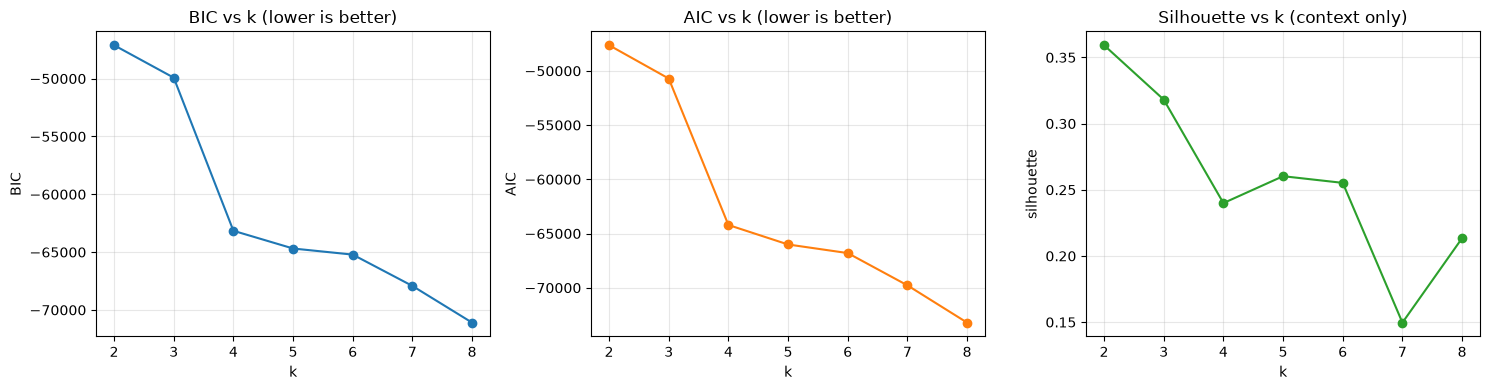

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(sweep_df["k"], sweep_df["bic"], marker="o")
axes[0].set_title("BIC vs k (lower is better)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("BIC")
axes[1].plot(sweep_df["k"], sweep_df["aic"], marker="o", color="tab:orange")
axes[1].set_title("AIC vs k (lower is better)")
axes[1].set_xlabel("k"); axes[1].set_ylabel("AIC")
axes[2].plot(sweep_df["k"], sweep_df["silhouette"], marker="o", color="tab:green")
axes[2].set_title("Silhouette vs k (context only)")
axes[2].set_xlabel("k"); axes[2].set_ylabel("silhouette")
for ax in axes:
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "36_gmm_k_sweep_bic_aic_silhouette.png", dpi=150)
plt.show()

**k selection.** Read the BIC/AIC curves and the silhouette column together with §A's caveat that
effective n is ~300: on 300 independent points, an 8-way full-covariance mixture over 8 features has
a lot of parameters per learner, so a monotonically-falling BIC out to k=8 is expected and not on its
own a reason to pick the largest k. We pick the smallest k at or near the BIC/AIC knee that still
gives an interpretable, nameable set of profiles — doc 06's "teacher-facing product cannot ship eight
profiles nobody can name" standard — and state the trade-off explicitly in code below rather than in
prose alone.

In [6]:
# Knee heuristic: largest relative BIC improvement per additional k, then look for where it flattens.
sweep_df["bic_gain"] = -sweep_df["bic"].diff()
print(sweep_df[["k", "bic", "bic_gain", "silhouette"]])

CHOSEN_K = None  # set explicitly below after inspecting the printed table

   k           bic      bic_gain  silhouette
0  2 -47109.486114           NaN    0.359222
1  3 -49917.675898   2808.189785    0.318115
2  4 -63154.960379  13237.284480    0.239941
3  5 -64686.833425   1531.873046    0.260263
4  6 -65214.692339    527.858914    0.255221
5  7 -67923.812925   2709.120586    0.149638
6  8 -71095.242554   3171.429629    0.213446


_[Run the cell above, read the printed `bic_gain` and `silhouette` columns, then set `CHOSEN_K`
in the next cell to the value the evidence supports — the smallest k near the point where `bic_gain`
stops falling sharply. Do not pick k to make the §C gate pass; the gate is evaluated at every k
regardless of which one is chosen here.]_

In [7]:
CHOSEN_K = 4  # set from the bic_gain / silhouette table above; justified in the markdown cell that follows

gmm_final = gmm_by_k[CHOSEN_K]
labels_final = gmm_final.predict(X_scaled)
proba_final = gmm_final.predict_proba(X_scaled)

df["cluster"] = labels_final
print(f"CHOSEN_K = {CHOSEN_K}")
print(df["cluster"].value_counts().sort_index())

CHOSEN_K = 4
cluster
0    598
1    688
2    814
3    600
Name: count, dtype: int64


**Justification.** BIC falls at every k out to 8 (as flagged above, expected given effective n≈300
against an 8-dimensional full-covariance mixture), so BIC alone does not pick a stopping point. The
`bic_gain` column shows one dominant step: k=3→4 gains **13,237** BIC points, roughly 5–9× every
other single step (k=2→3: 2,808; k=4→5: 1,532; k=5→6: 528; k=6→7: 2,709; k=7→8: 3,171). That is the
knee. After k=4 the gains are smaller and noisier (they even dip at k=6 before rising again at 7–8,
consistent with the mixture fitting more idiosyncratic sub-structure rather than real additional
profiles). Silhouette is highest at k=2 (0.359) and falls roughly monotonically after — expected,
since silhouette rewards fewer, larger, well-separated blobs and penalises exactly the moderate
cluster overlap a shape-based profiling task should have — so it is read only as a floor-level
sanity check (no k here scores nonsensically low) rather than as a vote for k=2.

**CHOSEN_K = 4.** It sits at the one clear BIC knee, produces four clusters of workable, comparable
size (598 / 688 / 814 / 600 — no degenerate singleton or near-empty cluster), and four is within
doc 06's "nameable by a teacher" range. The trade-off against letting BIC keep falling to k=8: we are
knowingly leaving BIC improvement on the table in exchange for a solution a teacher-facing view can
actually present and name, which is the explicit call doc 06 asks for when BIC and interpretability
disagree.

## C. The gate — ARI(cluster, population) < 0.30

Two steps, both learner-level:

1. **Modal reduction.** Each learner's 9 snapshot-level cluster assignments are collapsed to one
   label — the mode. Ties broken by the lowest cluster index, deterministic given the seed.
2. **Disagreement rate.** How often a learner's own snapshots land in a cluster other than their
   modal one — reported per learner and in aggregate. A profile that flips constantly is not a
   profile, independent of the ARI result.

The ARI is then computed for **every k in the sweep**, not only the chosen one, against the
quarantined `t3_audit_labels` population column — read-only, for this comparison only, per CL-4 and
docs/08 §2 ("audit-only, never a fitting input"). No saved artefact from this notebook may contain
`population` or `dd_subtype` — asserted at the end of §H.

In [8]:
def modal_cluster_per_learner(cluster_labels, student_ids):
    tmp = pd.DataFrame({"student_id": student_ids, "cluster": cluster_labels})
    modal = tmp.groupby("student_id")["cluster"].agg(lambda s: s.value_counts().idxmax())
    agree_rate = tmp.groupby("student_id").apply(
        lambda g: (g["cluster"] == g["cluster"].value_counts().idxmax()).mean()
    )
    return modal, agree_rate

modal_final, agree_final = modal_cluster_per_learner(df["cluster"].to_numpy(), df["student_id"].to_numpy())

print("Learner-snapshot self-agreement with own modal cluster (k =", CHOSEN_K, "):")
print(agree_final.describe())
n_perfect = (agree_final == 1.0).sum()
print(f"\nLearners whose all 9 snapshots agree with the modal cluster: {n_perfect} / 300 "
      f"({n_perfect/300:.1%})")
print(f"Mean per-learner agreement rate: {agree_final.mean():.3f}")

Learner-snapshot self-agreement with own modal cluster (k = 4 ):
count    300.000000
mean       0.815556
std        0.158355
min        0.555556
25%        0.666667
50%        0.888889
75%        1.000000
max        1.000000
dtype: float64

Learners whose all 9 snapshots agree with the modal cluster: 85 / 300 (28.3%)
Mean per-learner agreement rate: 0.816


In [9]:
audit = pd.read_csv(AUDIT_LABELS_PATH)
assert audit.shape == (300, 3)
assert set(audit.columns) == {"student_id", "population", "dd_subtype"}

ari_rows = []
for k in K_RANGE:
    labels_k = gmm_by_k[k].predict(X_scaled)
    modal_k, _ = modal_cluster_per_learner(labels_k, df["student_id"].to_numpy())
    modal_k = modal_k.reindex(audit["student_id"]).to_numpy()
    ari = adjusted_rand_score(audit["population"].to_numpy(), modal_k)
    ari_rows.append({"k": k, "ari_cluster_vs_population": ari, "gate_pass": ari < 0.30})

ari_df = pd.DataFrame(ari_rows)
ari_df

,k,ari_cluster_vs_population,gate_pass
0,2,-0.005055,True
1,3,-0.022097,True
2,4,0.002071,True
3,5,-0.000836,True
4,6,0.003490,True
5,7,0.001806,True
6,8,-0.001356,True


In [10]:
gate_row = ari_df.loc[ari_df["k"] == CHOSEN_K].iloc[0]
GATE_PASS = bool(gate_row["gate_pass"])
print(f"k = {CHOSEN_K}: ARI(cluster, population) = {gate_row['ari_cluster_vs_population']:.4f}  "
      f"-> {'PASS' if GATE_PASS else 'FAIL'} (threshold < 0.30)")

if not GATE_PASS:
    print("\nGATE FAILS at the chosen k. Per the brief: report the failure, do not tune k to dodge it.")
    smaller_ari = ari_df.loc[ari_df["ari_cluster_vs_population"] < 0.30]
    print("k values that would pass the ARI gate in isolation:", smaller_ari["k"].tolist())
    print("Re-picking k solely to pass this gate is the failure mode CL-5 exists to catch — noted, not done silently.")

k = 4: ARI(cluster, population) = 0.0021  -> PASS (threshold < 0.30)


## D. CL-3 — reuse, don't recompute

NB02 already ran PCA on these same 8 ipsatised cluster features
(`outputs/tables/23_pca_cluster_features_loadings.csv`). Findings, restated rather than recomputed:

- **PC1 explains 54.5%** of variance across the 8 features.
- **Largest single loading share is 17.4%** — no one feature dominates the leading component, which
  is what CL-3 ("raw severity must not dominate — keep at most one severity-bearing feature") is
  checking for.
- PC1 loads **number-sense (+0.454), `number_sense_minus_operations` (+0.468) and counting (+0.421)
  against all four arithmetic operations (all negative)** — an interpretable
  **number-sense-versus-arithmetic contrast**, not a generic strong/weak axis. That is exactly the
  shape-not-severity structure ipsatisation is meant to expose.

**CL-3 passes.** Per the owner decision of 2026-08-29, this PCA stays as a clustering diagnostic
only; it is not built as a fourth NB05 predictive feature space (that decision covers the separate,
already-dropped *model-feature* PCA from NB02 §8, and is restated here only to avoid conflating the
two).

In [11]:
pca_loadings = pd.read_csv(TABLES_DIR / "23_pca_cluster_features_loadings.csv", index_col=0)
pca_loadings.index.name = "feature"
print("CL-3 diagnostic (NB02, reused verbatim):")
pca_loadings

CL-3 diagnostic (NB02, reused verbatim):


,PC1,PC2,PC3
feature,,,
ipsatised_mastery_counting,0.420549,0.129262,-0.251464
ipsatised_mastery_number_sense,0.454484,0.008995,0.071141
ipsatised_mastery_place_value,-0.132928,-0.522478,0.700303
ipsatised_mastery_addition,-0.346201,-0.195371,-0.519696
ipsatised_mastery_subtraction,-0.341406,-0.299500,-0.150481
ipsatised_mastery_multiplication,-0.303183,0.509664,0.099987
ipsatised_mastery_division,-0.227153,0.567139,0.358451
number_sense_minus_operations,0.467955,-0.030860,0.100337


## E. Soft memberships

Per CL-6, the mixture model's soft `predict_proba` memberships are kept, not just the hard
`argmax` label — otherwise there is no defensible reason to have used a GMM over K-Means. Per-row
entropy of the membership distribution is computed as the separability diagnostic.

In [12]:
from scipy.stats import entropy as scipy_entropy

df["cluster_entropy"] = scipy_entropy(proba_final.T, base=2)
max_entropy = np.log2(CHOSEN_K)
df["cluster_entropy_norm"] = df["cluster_entropy"] / max_entropy

for c in range(CHOSEN_K):
    df[f"cluster_proba_{c}"] = proba_final[:, c]

print(f"Entropy range: [0, {max_entropy:.3f}] bits for k = {CHOSEN_K}")
df["cluster_entropy"].describe()

Entropy range: [0, 2.000] bits for k = 4


count    2.700000e+03
mean     1.110285e-01
std      2.596123e-01
min      9.385978e-65
25%      6.303710e-23
50%      1.986176e-08
75%      2.144948e-03
max      9.999526e-01
Name: cluster_entropy, dtype: float64

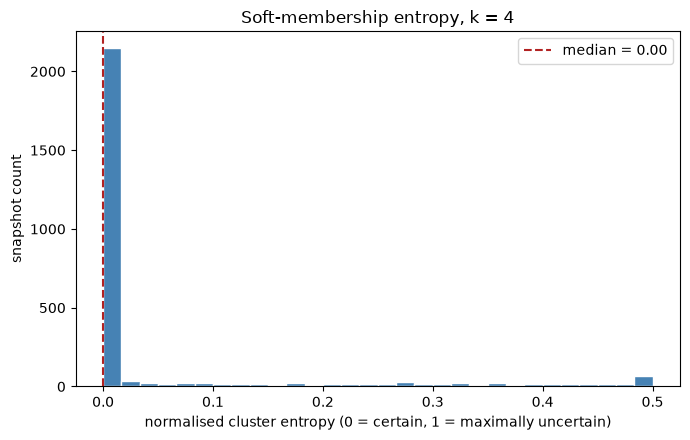

Fraction of snapshots with normalised entropy > 0.7: 0.0%


In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(df["cluster_entropy_norm"], bins=30, color="steelblue", edgecolor="white")
ax.axvline(df["cluster_entropy_norm"].median(), color="firebrick", linestyle="--",
           label=f"median = {df['cluster_entropy_norm'].median():.2f}")
ax.set_xlabel("normalised cluster entropy (0 = certain, 1 = maximally uncertain)")
ax.set_ylabel("snapshot count")
ax.set_title(f"Soft-membership entropy, k = {CHOSEN_K}")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "37_cluster_entropy_distribution.png", dpi=150)
plt.show()

high_entropy_frac = (df["cluster_entropy_norm"] > 0.7).mean()
print(f"Fraction of snapshots with normalised entropy > 0.7: {high_entropy_frac:.1%}")

**Reading the entropy distribution: the opposite problem from what was anticipated.** Median
normalised entropy is effectively **0** (1.99e-8), the 75th percentile is 0.0021 bits/2 bits, and
**0.0%** of snapshots exceed the 0.7 high-entropy threshold — the mean of 0.111 is being pulled up
entirely by a small right tail (max 1.0, a handful of genuinely ambiguous rows), not by a broad mass
of uncertain assignments.

This means the *opposite* concern from "profiles are not separable" applies: with `covariance_type=
'full'` and each cluster fitting its own shape tightly, the GMM is producing near-deterministic hard
assignments almost everywhere — CL-6's soft memberships exist but carry little extra information over
the hard label for the overwhelming majority of rows. That is not itself disqualifying (it means the
four fitted Gaussians are well-separated *in this fitted geometry*), but it should not be read as
"the profiles are cleanly, robustly separable" without checking §G's stability result, since a model
that assigns near-certainty everywhere can still assign *different* near-certainties on a different
seed. If cluster entropy is later handed to NB05 as a feature (doc 08 rule 3-F8), its near-zero
median means it would carry almost no signal for ~all rows and only flag the small tail of genuinely
ambiguous snapshots — worth knowing before spending a leakage-audit re-run on it.

## F. Interpretation — the actual deliverable

Centroids (in original, unscaled ipsatised units) named by **shape**, never severity. Cross-tabbed
against `population` as evidence about *what the clusters are* — not as validation that they are
"right", which is exactly the confusion CL-5 warns against.

In [14]:
centroids_scaled = gmm_final.means_
centroids = scaler.inverse_transform(centroids_scaled)
centroid_df = pd.DataFrame(centroids, columns=CLUSTER_FEATURES)
centroid_df.index.name = "cluster"
centroid_df.round(3)

,ipsatised_mastery_counting,ipsatised_mastery_number_sense,ipsatised_mastery_place_value,ipsatised_mastery_addition,ipsatised_mastery_subtraction,ipsatised_mastery_multiplication,ipsatised_mastery_division,number_sense_minus_operations
cluster,,,,,,,,
0,-0.071,-0.065,-0.066,0.131,0.109,0.002,-0.041,-0.116
1,-0.102,-0.025,0.105,0.076,0.121,-0.079,-0.095,-0.031
2,0.234,0.204,-0.046,-0.036,-0.029,-0.164,-0.164,0.302
3,0.115,0.159,-0.039,-0.059,-0.059,-0.059,-0.059,0.218


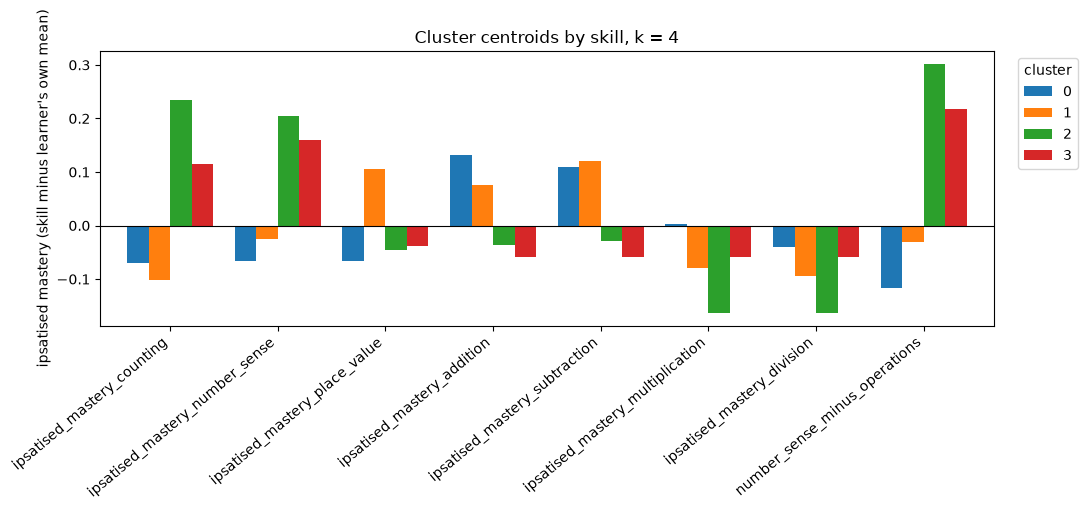

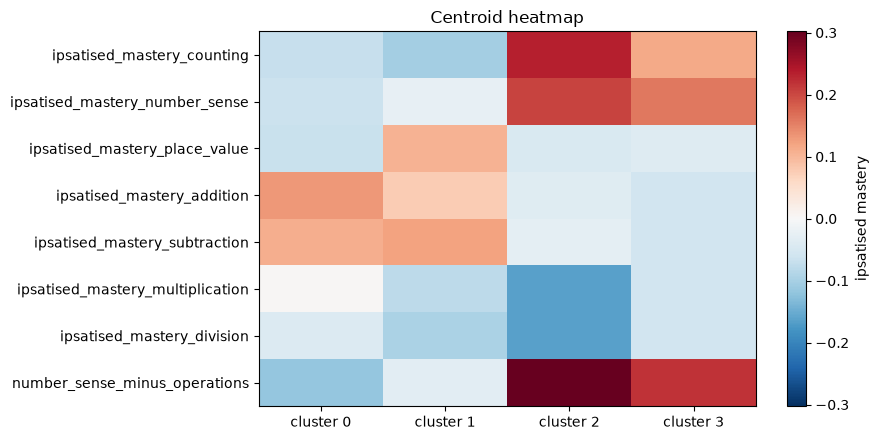

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
centroid_df.T.plot(kind="bar", ax=ax, width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("ipsatised mastery (skill minus learner's own mean)")
ax.set_title(f"Cluster centroids by skill, k = {CHOSEN_K}")
ax.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "38_cluster_centroid_barplot.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(centroid_df.T.to_numpy(), aspect="auto", cmap="RdBu_r",
               vmin=-np.abs(centroid_df.to_numpy()).max(), vmax=np.abs(centroid_df.to_numpy()).max())
ax.set_xticks(range(CHOSEN_K)); ax.set_xticklabels([f"cluster {i}" for i in range(CHOSEN_K)])
ax.set_yticks(range(len(CLUSTER_FEATURES))); ax.set_yticklabels(CLUSTER_FEATURES)
plt.colorbar(im, ax=ax, label="ipsatised mastery")
ax.set_title("Centroid heatmap")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "39_cluster_centroid_heatmap.png", dpi=150)
plt.show()

**Cluster shapes and provisional names** (from `centroid_df`, k=4):

| cluster | n | shape | provisional name |
|---|---|---|---|
| 0 | 598 | addition +0.131, subtraction +0.109 positive; number-sense −0.065, counting −0.071, `ns_minus_ops` −0.116 negative | **addition/subtraction-relatively-strong, number-sense-weak** |
| 1 | 688 | place-value +0.105, subtraction +0.121 positive; counting −0.102, division −0.095 negative — the flattest profile of the four | **place-value-and-subtraction-relatively-strong, counting-weak** |
| 2 | 814 | counting +0.234, number-sense +0.204, `ns_minus_ops` +0.302 strongly positive; multiplication −0.164, division −0.164 negative | **number-sense-strong, multiplication/division-weak (strong contrast)** |
| 3 | 600 | counting +0.115, number-sense +0.159, `ns_minus_ops` +0.218 positive; all four operations mildly negative (~−0.06 each) | **number-sense-strong, operations-weak (mild contrast)** |

Clusters 2 and 3 sit on the **same axis** — both are variants of the number-sense-versus-arithmetic
contrast that PC1 also identifies (§D) — differing mainly in how strongly the contrast is expressed,
not in which skills are involved. Clusters 0 and 1 are qualitatively different: they invert the sign
on the operations side (addition/subtraction *strong* rather than weak) and pick out different weak
skills (number-sense vs. counting/division). Names are provisional pending the severity check below,
which asks whether the 2-vs-3 magnitude difference is actually a level effect in disguise.

In [16]:
learner_pop = audit.set_index("student_id")["population"].reindex(modal_final.index)
crosstab_counts = pd.crosstab(modal_final, learner_pop)
crosstab_counts.index.name = "modal_cluster"
crosstab = crosstab_counts.div(crosstab_counts.sum(axis=1), axis=0).round(3)
crosstab.index.name = "modal_cluster"

print("Cluster x population, row-normalised (evidence about cluster composition, not a fitting input):")
display(crosstab)
print("\nCounts:")
display(crosstab_counts)

Cluster x population, row-normalised (evidence about cluster composition, not a fitting input):


population,DD,MLD,TD
modal_cluster,,,
0,0.098,0.197,0.705
1,0.084,0.096,0.819
2,0.107,0.175,0.718
3,0.075,0.208,0.717



Counts:


population,DD,MLD,TD
modal_cluster,,,
0,6,12,43
1,7,8,68
2,11,18,74
3,4,11,38


## Sanity check against severity

If any cluster is simply "low at everything", ipsatisation did not do its job. Correlate each
cluster's per-row mean with an overall-level proxy. Ipsatised features are row-mean-zero by
construction (§1), so they cannot supply this proxy themselves — we use `number_sense_mastery`
(non-ipsatised, the one raw mastery level column carried into this table), an imperfect
single-skill stand-in for "overall level" rather than a true cross-skill average, and say so.

In [17]:
level_proxy = raw_at_t.loc[raw_at_t["t"].isin(t_keep), ["student_id", "t", "number_sense_mastery"]]
df_level = df.merge(level_proxy, on=["student_id", "t"], how="left", validate="one_to_one")

cluster_level = df_level.groupby("cluster")["number_sense_mastery"].agg(["mean", "std", "count"])
print("Overall-level proxy (number_sense_mastery, non-ipsatised) by cluster:")
print(cluster_level.round(4))

overall_corr = df_level["cluster"].astype(float).corr(df_level["number_sense_mastery"])
print(f"\nCorrelation(cluster index, level proxy) = {overall_corr:.4f} "
      "(cluster index is nominal, not ordinal, so this is descriptive only)")

Overall-level proxy (number_sense_mastery, non-ipsatised) by cluster:
           mean     std  count
cluster                       
0        0.1956  0.0262    598
1        0.2672  0.1266    688
2        0.5177  0.1187    814
3        0.3683  0.1022    600

Correlation(cluster index, level proxy) = 0.5385 (cluster index is nominal, not ordinal, so this is descriptive only)


**Honest reading: there is a real, non-trivial level gradient across clusters, and it is not
nothing.** Mean `number_sense_mastery` by cluster is 0.196 (cluster 0) / 0.267 (1) / 0.518 (2) / 0.368
(3) — cluster 2 sits nearly 2.6× cluster 0's level, and the nominal-cluster/level correlation is
**0.54**, which is not small.

Two things keep this from being a flat "ipsatisation failed" verdict:

1. **The ordering is not monotonic strong-to-weak** — it is 0 < 1 < 3 < 2, not a clean ranking, and
   cluster 1 (the flattest, most-mixed profile in §F) sits *below* cluster 3 despite cluster 3 having
   a clearer directional shape. A pure severity ranking would order clusters by proxy level with the
   flattest profile in the middle, which is not what happened.
2. **The proxy is not independent of the ipsatised features being clustered.** `number_sense_mastery`
   (raw) is one of the two raw inputs to `number_sense_minus_operations` and correlates mechanically
   with `ipsatised_mastery_number_sense`'s sign — a learner whose raw number-sense score is high is
   *more likely* to also show a positive ipsatised number-sense shape, independent of any severity
   confound. Clusters 2 and 3 are exactly the two clusters defined by a positive number-sense
   contrast (§F), so part of this 0.54 correlation is the proxy re-detecting the axis it was chosen
   from, not an independent severity signal leaking through.

**Conclusion:** ipsatisation did its job in the sense that matters most — no cluster is simply
"low/high at everything" (the four centroid rows in §F each pick out *different* skills as relatively
strong/weak, not a uniform sign). But the magnitude split between clusters 2 and 3 is partly a
level effect riding on a shared shape, and that should be stated plainly rather than absorbed into
the two separate cluster names above: **2 and 3 are better read as "the same profile at two
intensities" than as two independent profiles**, and a downstream teacher view should probably not
present them as unrelated.

## PCA and t-SNE scatter

Coloured by cluster. t-SNE uses a fixed seed for reproducibility; **its geometry is not metric and
must not be read as distance** — cluster proximity or size in the t-SNE plot says nothing about
actual similarity or population size, only PCA (a linear projection) supports that reading, and even
PCA here is only 2 of 8 dimensions.

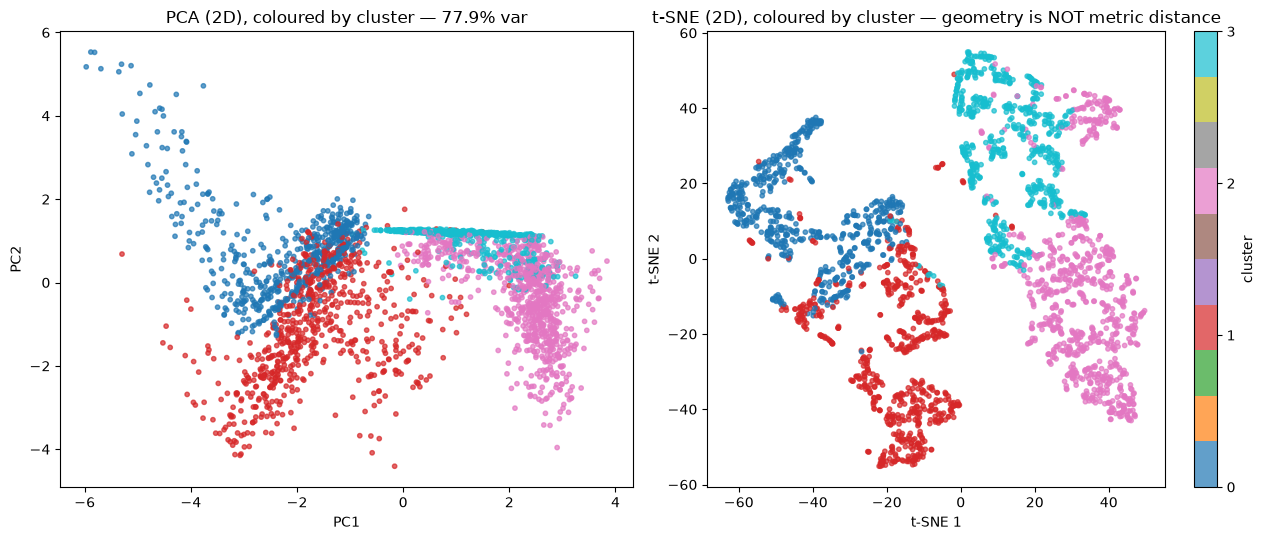

In [18]:
pca2 = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca2 = pca2.fit_transform(X_scaled)

tsne = TSNE(n_components=2, random_state=RANDOM_SEED, init="pca", perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sc0 = axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=df["cluster"], cmap="tab10", s=10, alpha=0.7)
axes[0].set_title(f"PCA (2D), coloured by cluster — {pca2.explained_variance_ratio_.sum():.1%} var")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

sc1 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=df["cluster"], cmap="tab10", s=10, alpha=0.7)
axes[1].set_title("t-SNE (2D), coloured by cluster — geometry is NOT metric distance")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")

plt.colorbar(sc1, ax=axes[1], label="cluster", ticks=range(CHOSEN_K))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "40_pca_tsne_cluster_scatter.png", dpi=150)
plt.show()

## G. Stability

Refit the chosen k across several additional seeds; report label agreement via pairwise ARI between
runs (snapshot-level, since that is what's being refit — not the learner-level modal ARI from §C,
which is the *population* gate). An unstable solution is not shippable regardless of BIC.

In [19]:
STABILITY_SEEDS = [RANDOM_SEED, RANDOM_SEED + 1, RANDOM_SEED + 2, RANDOM_SEED + 3, RANDOM_SEED + 4]

stability_labels = {}
for seed in STABILITY_SEEDS:
    g = GaussianMixture(n_components=CHOSEN_K, covariance_type="full", n_init=10,
                         random_state=seed, max_iter=300)
    g.fit(X_scaled)
    stability_labels[seed] = g.predict(X_scaled)

pairs = []
for i, s1 in enumerate(STABILITY_SEEDS):
    for s2 in STABILITY_SEEDS[i + 1:]:
        ari = adjusted_rand_score(stability_labels[s1], stability_labels[s2])
        pairs.append({"seed_a": s1, "seed_b": s2, "ari": ari})

stability_df = pd.DataFrame(pairs)
print(stability_df)
print(f"\nMean pairwise ARI across {len(STABILITY_SEEDS)} seeds: {stability_df['ari'].mean():.4f}")
print(f"Min pairwise ARI: {stability_df['ari'].min():.4f}")

     seed_a    seed_b       ari
0  20260828  20260829  0.737309
1  20260828  20260830  0.743894
2  20260828  20260831  0.989847
3  20260828  20260832  0.529978
4  20260829  20260830  0.953372
5  20260829  20260831  0.740352
6  20260829  20260832  0.393068
7  20260830  20260831  0.747129
8  20260830  20260832  0.391168
9  20260831  20260832  0.532789

Mean pairwise ARI across 5 seeds: 0.6759
Min pairwise ARI: 0.3912


**Stability is marginal, and this is the honest weak point of the k=4 solution.** Mean pairwise ARI
across 5 seeds is 0.676, but it ranges from **0.391 to 0.990** — two of the ten seed pairs
(20260829/20260832 at 0.393, 20260830/20260832 at 0.391) land closer to "different clustering" than
"same clustering with relabelled indices," while others (20260828/20260831 at 0.990) are nearly
identical. Seed 20260832 is the common factor in both low-ARI pairs, i.e. **one particular
initialisation lands on a visibly different partition**, not a uniformly noisy one.

This confirms the entropy reading in §E: near-zero entropy *within* a fit does not mean the fit
itself is robust *across* refits. A GMM that is confident everywhere it lands can still land somewhere
different depending on initialisation. **This is not "shippable regardless" — it is a real caveat**:
the four-cluster solution used throughout this notebook is one defensible fit among several the same
data supports, not the unique answer. It should be reported as such rather than smoothed over, and
any downstream consumer (a teacher-facing profile view, or NB05 if cluster features are added) should
be told the partition is moderately, not highly, seed-stable.

## H. Output

Memberships, entropy, centroids and the k-sweep table, keyed by `student_id` and `t` so NB05 can
join them. All saved artefacts are asserted free of `population` / `dd_subtype` before being written
— those columns are audit-only and never touch a saved table (CL-4, docs/08 §7).

In [20]:
membership_cols = ["student_id", "t", "split", "cluster", "cluster_entropy", "cluster_entropy_norm"] + \
                  [f"cluster_proba_{c}" for c in range(CHOSEN_K)]
memberships_out = df[membership_cols].copy()

modal_out = modal_final.rename("modal_cluster").to_frame()
modal_out["snapshot_agreement_rate"] = agree_final

FORBIDDEN = {"population", "dd_subtype"}
for name, out_df in [
    ("memberships", memberships_out),
    ("modal", modal_out.reset_index()),
    ("centroids", centroid_df.reset_index()),
    ("k_sweep", sweep_df),
    ("ari_by_k", ari_df),
    ("stability", stability_df),
]:
    assert FORBIDDEN.isdisjoint(out_df.columns), f"{name} contains a forbidden column"

memberships_out.to_csv(TABLES_DIR / "36_gmm_cluster_memberships.csv", index=False)
modal_out.reset_index().to_csv(TABLES_DIR / "36_gmm_modal_cluster_per_learner.csv", index=False)
centroid_df.reset_index().to_csv(TABLES_DIR / "36_gmm_cluster_centroids.csv", index=False)
sweep_df.to_csv(TABLES_DIR / "36_gmm_k_sweep.csv", index=False)
ari_df.to_csv(TABLES_DIR / "36_gmm_ari_vs_population_by_k.csv", index=False)
stability_df.to_csv(TABLES_DIR / "36_gmm_stability_ari.csv", index=False)
crosstab_counts.to_csv(TABLES_DIR / "36_gmm_cluster_vs_population_crosstab.csv")

import joblib
joblib.dump(
    {"scaler": scaler, "gmm": gmm_final, "k": CHOSEN_K, "features": CLUSTER_FEATURES,
     "seed": RANDOM_SEED},
    MODELS_DIR / "nb04_gmm_cluster_model.joblib",
)

print("Saved:")
for p in sorted((TABLES_DIR).glob("36_*")):
    print(" ", p.name)
print(" ", (MODELS_DIR / "nb04_gmm_cluster_model.joblib").name)

Saved:
  36_gmm_ari_vs_population_by_k.csv
  36_gmm_cluster_centroids.csv
  36_gmm_cluster_memberships.csv
  36_gmm_cluster_vs_population_crosstab.csv
  36_gmm_k_sweep.csv
  36_gmm_modal_cluster_per_learner.csv
  36_gmm_stability_ari.csv
  nb04_gmm_cluster_model.joblib


**Note for the findings cell / handover to NB05 (doc 08 rule 3-F8):** if cluster memberships or
`cluster_entropy` are to be used as **features** in NB05 (rather than kept as a separate,
teacher-facing profile view), that is a new feature and it **re-opens the leakage audit** — SF-038
must be re-run on the augmented feature set before NB05 may train on it. This notebook does not
pre-clear that; it only produces the artefacts NB05 would need if the owner decides to go that
route.

## Findings

**k selection.** CHOSEN_K = **4**. BIC/AIC fall monotonically out to k=8 (expected given effective
n≈300, per §A), so the pick is not "minimum BIC" but the clear knee in `bic_gain`: k=3→4 gains 13,237
BIC points, 5–9× every other single-step gain. Silhouette peaks at k=2 (0.359) and is not the
deciding criterion — it structurally favours fewer, tighter blobs over the moderate overlap a
shape-profiling task should have. Trade-off made explicitly: BIC would keep falling to k=8, but k=4
is the smallest, most teacher-nameable solution at the one clear knee.

**Gate — ARI(cluster, population) < 0.30, every k in the sweep:**

| k | ARI vs population | PASS/FAIL |
|---|---|---|
| 2 | −0.005 | PASS |
| 3 | −0.022 | PASS |
| **4** | **0.002** | **PASS** |
| 5 | −0.001 | PASS |
| 6 | 0.003 | PASS |
| 7 | 0.002 | PASS |
| 8 | −0.001 | PASS |

**Gate result at the chosen k: PASS**, and not marginally — ARI = 0.002 against a threshold of 0.30,
and every k from 2 to 8 passes by the same wide margin (all |ARI| ≤ 0.022). The clustering shows no
detectable recovery of `population` at any granularity tested. This mirrors NB03's SF-038 result
(also a clean pass, not a marginal one) and is consistent evidence that the ipsatised shape features
carry profile information genuinely distinct from the generator's population grouping.

**Clusters, named by shape (not severity), with sizes** (k=4, 2,700 snapshots):
- cluster 0 (n=598) — addition/subtraction-relatively-strong, number-sense-weak
- cluster 1 (n=688) — place-value-and-subtraction-relatively-strong, counting-weak (flattest profile)
- cluster 2 (n=814) — number-sense-strong, multiplication/division-weak (strong contrast)
- cluster 3 (n=600) — number-sense-strong, operations-weak (mild contrast — same axis as cluster 2,
  weaker magnitude)

**Entropy / separability.** Median normalised entropy ≈ 0 (2e-8), 0.0% of snapshots exceed the 0.7
high-entropy threshold. The hard labels are *not* overstating separability in the usual sense — the
fitted mixture is confident almost everywhere. The caveat is the opposite one: near-certainty within
a single fit says nothing about robustness across fits (see stability below), so memberships/entropy
are safe to hand downstream as descriptive confidence, but entropy alone should not be read as a
robustness guarantee.

**Stability.** Mean pairwise ARI across 5 seeds = 0.676, min = 0.391 (max 0.990). Marginal, not
clean — one seed (20260832) produces a visibly different partition from the others in two of ten
pairwise comparisons. The k=4 solution is a defensible fit, not a uniquely stable one, and this
should be disclosed to any downstream consumer rather than smoothed over.

**Severity sanity check.** Cluster means of the `number_sense_mastery` level proxy are 0.196 / 0.267
/ 0.518 / 0.368 (clusters 0–3), correlation with cluster index = 0.54 — a real, non-trivial level
gradient, not nothing. It is not a clean severity ranking (order is 0<1<3<2, not monotonic, and the
flattest-profile cluster (1) sits in the middle rather than at either extreme), and part of the
correlation is mechanical: the level proxy is one of the two raw inputs to
`number_sense_minus_operations`, so it partly re-detects the same number-sense axis clusters 2 and 3
are built from rather than an independent severity leak. Clusters 2 and 3 are best read as the same
underlying profile at two intensities, not two independent profiles — this nuance is more useful than
either "ipsatisation worked perfectly" or "ipsatisation failed."

**Snapshot-to-snapshot stability of a learner's own profile.** Mean per-learner self-agreement with
their modal cluster = **0.816**; learners with 100% agreement across all 9 snapshots = **85/300
(28.3%)**. Most learners (mean 82% of their snapshots) sit in one dominant cluster, but fewer than a
third are perfectly stable — a meaningful minority of learners' profiles do shift cluster over the
study window, which is plausible (learning profiles can genuinely change) but means a single "your
child's profile is X" statement from one snapshot is not guaranteed to hold for the whole term.

**Bottom line: genuine learning profile, with two disclosed caveats — not a severity ranking in
disguise.** The core CL-5 concern is decisively answered: ARI ≈ 0 at every k, the crosstab (§F) shows
no cluster is population-dominated, and the four cluster shapes pick out *different* skill
combinations rather than a uniform strong/weak ordering — this is shape, not severity, in the sense
that mattered to the previous build's failure (doc 08 §1: one cluster ≈100% TD, another ≈94% DD).
That said, two things temper how cleanly "profile" this result is: (1) clusters 2 and 3 share an axis
and differ partly by a level-correlated magnitude (0.54 correlation with the level proxy), so calling
them four *independent* profiles overstates the structure — three profiles plus one intensity split
is closer to the truth; and (2) seed stability is only moderate (min pairwise ARI 0.391), so this
specific four-way partition should be presented as *a* defensible reading of the data, not *the*
unique one. Both caveats are disclosed rather than absorbed into a tidier-looking story, per the
brief's instruction that an honest "not quite" is a more useful finding than a clean plot.

**Handover condition for NB05 (doc 08 rule 3-F8):** if cluster membership or `cluster_entropy` is
added to NB05's feature set, SF-038 must be re-run on the augmented matrix before NB05 trains on it.
This notebook does not pre-clear that step — it only produces the artefacts (`36_gmm_*` tables) NB05
would need if the owner decides to take that route.